# Mover átomos por interpolación lineal de fase: la secuencia de hologramas de un ordenamiento

**Pregunta:** Una vez fijada la asignación, ¿la secuencia de hologramas que construye M16 por interpolación lineal de fase mantiene brillantes las trampas en movimiento, y lo hace mejor que calcular cada paso por separado?

- Nivel: 3, estado del arte. Método ejecutado: M16.
- Requisitos previos: `07-feedback-and-dynamics/02-assigning-atoms-to-sites`, que construye la asignación y el plan.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en cerca de un minuto.

## Objetivos

Mover una trampa con un SLM significa mostrar una secuencia de hologramas. Si cada holograma se calcula por separado, las fases libres de las trampas son las que encuentra el algoritmo, saltan de un paso al siguiente, y la luz que suman dos puntos vecinos en la posición de un punto en movimiento cambia con ellas: el punto parpadea, y se puede perder un átomo. La interpolación lineal de fase (LPI) es la respuesta publicada, y M16 la implementa. Al terminar puedes:

- decir cómo construye LPI los hologramas intermedios de un movimiento a partir de los dos hologramas extremos;
- medir la caída de cada trampa en movimiento a lo largo de la secuencia para dos exponentes de la asignación;
- comparar LPI con un holograma independiente para cada paso, sobre los mismos movimientos;
- decir qué le hace a las caídas un paso más fino;
- decir qué parte de la respuesta es un modelo y cuál es una medición.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.cases.library import random_loading
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.forward import point_trap_fields
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget, Target
from dataclasses import replace
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.methods.baseline import m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond.b2_flicker_bounded import trajectory, transient_min_ratio
from pipeline.model.holo.methods.control import m16_rearrangement
from pipeline.model.holo.methods.control.m16_rearrangement import assign, count_crossings

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C10 de `data/examples/cases.json`: un arreglo de 10 x 10 sitios con un espaciado de cerca de 8 bins focales, una probabilidad de carga de 0,55 y un bloque de 36 sitios objetivo en el centro.

- Propietario: este repositorio; el caso es sintético, y la carga se sortea con el generador portátil y la semilla del registro.
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C10 (el bloque `rearrangement` lleva la probabilidad de carga, los identificadores objetivo y el exponente).

In [2]:
# caso C10: un arreglo de 10 x 10 sitios, cargado al azar, y un bloque de 6 x 6 por llenar
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C10"]
setup = build.setup_of(rec)
sites = {t["id"]: t for t in rec["target"]["traps"]}
loaded = random_loading(rec)
wanted = rec["rearrangement"]["target_ids"]
empty = sorted(set(wanted) - set(loaded))
surplus = sorted(set(loaded) - set(wanted))
print(rec["case_id"], "|", len(sites), "sitios | probabilidad de carga", rec["rearrangement"]["loading_p"])
print(f"átomos cargados: {len(loaded)} | sitios objetivo: {len(wanted)} | "
      f"sitios objetivo vacíos: {len(empty)} | átomos sobrantes: {len(surplus)}")

C10_rearrangement | 100 sitios | probabilidad de carga 0.55
átomos cargados: 52 | sitios objetivo: 36 | sitios objetivo vacíos: 16 | átomos sobrantes: 32


## Método

M16 calcula el holograma de las posiciones iniciales y el de las finales, ambos con GS ponderado de fase fija (Kim et al., 2019), lee de cada uno la posición, la amplitud y la fase óptica de cada pinza, y construye los cuadros intermedios interpolándolos linealmente en $S$ pasos: $x_m(s) = x_m^\text{i} + (s/S)(x_m^\text{f} - x_m^\text{i})$ para la posición, lo mismo para la amplitud, y para la fase la diferencia envuelta, $\psi_m(s) = \psi_m^\text{i} + (s/S)\,\mathrm{wrap}(\psi_m^\text{f} - \psi_m^\text{i})$. Cada cuadro es la transformada inversa de la superposición de los puntos interpolados, sin optimización propia (la receta de arXiv 2501.01391; la diferencia de fase envuelta es la lectura que el pipeline hace de ella). El número de pasos es $S = \lceil d_\text{máx} / s_\text{máx} \rceil$ con el movimiento más largo $d_\text{máx}$ y un paso $s_\text{máx}$ de dos bins por defecto. El ordenamiento es el del notebook anterior, caso C10: 52 átomos cargados, 36 sitios objetivo.

## Estado del arte

LPI es el estado del arte para la luz de un ordenamiento, y sus autores informan que las trampas en movimiento se mantienen sobre 70 por ciento de su intensidad donde hologramas independientes de GS ponderado hacen que el punto casi desaparezca. No existe una implementación de referencia fijada de ella entre las dependencias del notebook (slmsuite no ofrece una secuencia de hologramas en movimiento), así que la línea base aquí es con la que compara el artículo, un holograma independiente para cada paso, calculado con el M07 propio de DinHot. Las celdas ejecutan M16 para los dos exponentes y miden las caídas.

### La secuencia de hologramas

Conocidos los caminos, la luz debe seguirlos. M16 calcula el holograma de las posiciones iniciales y el de las finales, ambos con GS ponderado de fase fija (30 iteraciones), lee de cada uno la posición, la amplitud y la fase óptica de cada pinza, y construye los cuadros intermedios por interpolación lineal de fase (LPI): la posición y la amplitud cambian linealmente en $S$ pasos, la fase por la diferencia envuelta, y cada cuadro es la transformada inversa de la superposición de los puntos interpolados (la receta de arXiv 2501.01391). Ningún cuadro se optimiza por separado. El número de pasos es $S = \lceil d_\text{máx} / s_\text{máx} \rceil$ con el movimiento más largo $d_\text{máx}$ y un paso $s_\text{máx}$ de dos bins, una unidad de Fourier. La celda lo ejecuta para el plan con $\alpha = 1{,}0$.

In [3]:
# M16 en el mismo ordenamiento con alpha = 1.0: dos hologramas WGS de fase fija y la interpolación lineal de
# fase entre ellos
atoms = build.trapset_of([sites[i] for i in loaded])
goal = Target.from_traps(build.trapset_of([sites[i] for i in wanted]))
seq10 = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.0)
moving10 = seq10.meta["moved"]
ratio10 = seq10.meta["min_ratio"][moving10]
print(f"alpha 1.0: {seq10.meta['n_steps']} pasos | {int(moving10.sum())} trampas en movimiento | "
      f"cruces {seq10.meta['crossings']}")
print(f"menor intensidad de una trampa en movimiento, relativa a su media: "
      f"min {ratio10.min():.3f}, mediana {np.median(ratio10):.3f}")

alpha 1.0: 15 pasos | 16 trampas en movimiento | cruces 0
menor intensidad de una trampa en movimiento, relativa a su media: min 0.710, mediana 0.857


El ordenamiento con $\alpha = 1{,}0$ toma 15 pasos para sus 16 trampas en movimiento, 0 cruces, y la menor intensidad que alcanza una trampa en movimiento, relativa a su propia media en la secuencia, es 0,710 (mediana 0,857). Sigue la misma secuencia con el exponente de Lee, Kim y Ahn.

In [4]:
# lo mismo con alpha = 1.5, el valor de Lee, Kim y Ahn
seq15 = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.5)
moving15 = seq15.meta["moved"]
ratio15 = seq15.meta["min_ratio"][moving15]
print(f"alpha 1.5: {seq15.meta['n_steps']} pasos | {int(moving15.sum())} trampas en movimiento | "
      f"cruces {seq15.meta['crossings']}")
print(f"menor intensidad de una trampa en movimiento, relativa a su media: "
      f"min {ratio15.min():.3f}, mediana {np.median(ratio15):.3f}")
print(f"fracción de trampas en movimiento que se mantienen sobre 0.7: "
      f"{np.mean(ratio10 >= 0.7):.3f} (alpha 1.0), {np.mean(ratio15 >= 0.7):.3f} (alpha 1.5)")

alpha 1.5: 9 pasos | 24 trampas en movimiento | cruces 1
menor intensidad de una trampa en movimiento, relativa a su media: min 0.690, mediana 0.836
fracción de trampas en movimiento que se mantienen sobre 0.7: 1.000 (alpha 1.0), 0.958 (alpha 1.5)


Con $\alpha = 1{,}5$ la secuencia necesita solo 9 pasos, porque el movimiento más largo es más corto, y mueve 24 trampas. La menor intensidad de una trampa en movimiento es 0,690 (mediana 0,836), y 95,8 por ciento de las trampas en movimiento se mantienen sobre 0,7 frente a todas ellas con $\alpha = 1{,}0$. El artículo de LPI informa que sus trampas en movimiento se mantienen sobre 70 por ciento de su intensidad, donde hologramas independientes de GS ponderado hacen que el punto casi desaparezca; la línea de 0,7 es la que conviene comparar.

Para ver una sola caída, la celda siguiente toma la trampa en movimiento más débil de la secuencia con $\alpha = 1{,}5$ y calcula su intensidad a partir del campo de cada cuadro, en la posición que el cuadro le da.

In [5]:
# la intensidad de la trampa en movimiento más débil de la secuencia con alpha = 1.5 en cada paso, a partir
# de los campos de los cuadros
weakest = int(np.flatnonzero(moving15)[np.argmin(ratio15)])
frames, steps_15 = seq15.meta["frames"], seq15.meta["trap_sequence"]
along = np.array([abs(point_trap_fields(frames[s], setup, steps_15[s])[weakest]) ** 2 for s in range(len(frames))])
allm = np.array([np.abs(point_trap_fields(frames[s], setup, steps_15[s])) ** 2 for s in range(len(frames))])
print(f"trampa en movimiento más débil, índice: {weakest} | media sobre la secuencia "
      f"{along.mean():.4f} | menor {along.min():.4f}")
print(f"intensidad media de las 36 trampas: {allm.mean():.4f}")

trampa en movimiento más débil, índice: 13 | media sobre la secuencia 0.0203 | menor 0.0140
intensidad media de las 36 trampas: 0.0200


El panel izquierdo grafica la intensidad de esa trampa frente al paso, relativa a su media en la secuencia, y el derecho hace el histograma de la menor intensidad relativa de cada trampa en movimiento para los dos exponentes.

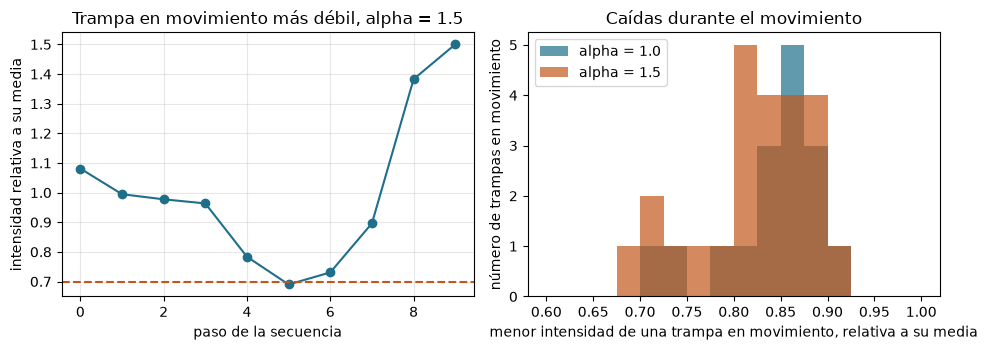

In [6]:
# intensidad de la trampa en movimiento más débil frente al paso, con la media sobre la secuencia y la línea
# de 70 %
fig, (a, b) = plt.subplots(1, 2, figsize=(9.6, 3.6))
a.plot(along / along.mean(), "o-", color="#1f6f8b")
a.axhline(0.7, color="#c2571a", linestyle="--")
a.set_xlabel("paso de la secuencia")
a.set_ylabel("intensidad relativa a su media")
a.set_title("Trampa en movimiento más débil, alpha = 1.5")
a.grid(True, alpha=0.3)
b.hist(ratio10, bins=np.linspace(0.6, 1.0, 17), alpha=0.7, label="alpha = 1.0", color="#1f6f8b")
b.hist(ratio15, bins=np.linspace(0.6, 1.0, 17), alpha=0.7, label="alpha = 1.5", color="#c2571a")
b.set_xlabel("menor intensidad de una trampa en movimiento, relativa a su media")
b.set_ylabel("número de trampas en movimiento")
b.set_title("Caídas durante el movimiento")
b.legend()
plt.tight_layout()
plt.show()

La trampa más débil tiene una intensidad media de 0,0203 en la secuencia, cerca de la media de 0,0200 de las 36 trampas, y cae a 0,0140 en el quinto paso, una caída a 0,690 de su media. Tras la caída sube a 1,5 veces su media en el último paso. El histograma tiene dos distribuciones superpuestas con máximo entre 0,8 y 0,9; la secuencia con $\alpha = 1{,}5$ tiene una cola izquierda más larga, hasta 0,69, porque mueve más trampas. La figura muestra que LPI mantiene las trampas en movimiento sobre 0,7 en todos los casos salvo uno, y no muestra nada sobre los instantes entre dos cuadros, donde el cristal líquido todavía se está relajando; el notebook de movimientos acotados en parpadeo añade ese modelo. También muestra una carga y una semilla.

### La línea base: un holograma independiente para cada paso

Para los 10 pasos de la secuencia con $lpha = 1{,}5$ la celda calcula un holograma WGS de fase fija separado en las posiciones de ese paso, con 12 iteraciones y sin vínculo con sus vecinos. Cada uno es perfecto en su propio paso, de modo que el parpadeo no está en los cuadros sino entre ellos, y la medida tiene que incluir la mezcla de dos cuadros consecutivos. La celda evalúa ambas secuencias con el modelo transitorio de B2, que mezcla el cuadro $s$ y el cuadro $s+1$ y lee cada trampa en su posición intermedia, con posiciones lineales en el paso, e imprime la menor intensidad de cada trampa en movimiento relativa a su media.

In [7]:
# la alternativa a LPI: un holograma WGS de fase fija independiente (12 iteraciones) para cada paso de la
# secuencia con alpha = 1.5
order = seq15.meta["assignment"]
origin = TrapSet(replace(t, x_m=atoms.x_m[order[i]], y_m=atoms.y_m[order[i]]) for i, t in enumerate(goal.traps))
along = trajectory(origin, goal.traps, len(steps_15), profile=lambda tau: tau)
free = [m07_phase_fixed_wgs.run(setup, Target.from_traps(ts), budget=Budget(12), rng=Rng(7)).phi for ts in steps_15]
ratios = {"LPI (M16)": transient_min_ratio(setup, list(frames), along)[moving15],
          "WGS independiente": transient_min_ratio(setup, free, along)[moving15]}
for name, r in ratios.items():
    print(f"{name:22s} menor {r.min():.3f} | mediana {np.median(r):.3f} | "
          f"fracción de trampas en movimiento en o sobre 0.7 {np.mean(r >= 0.7):.3f}")

LPI (M16)              menor 0.430 | mediana 0.652 | fracción de trampas en movimiento en o sobre 0.7 0.333
WGS independiente      menor 0.163 | mediana 0.645 | fracción de trampas en movimiento en o sobre 0.7 0.333


La figura ordena la menor intensidad de cada trampa en movimiento, para ambas secuencias.

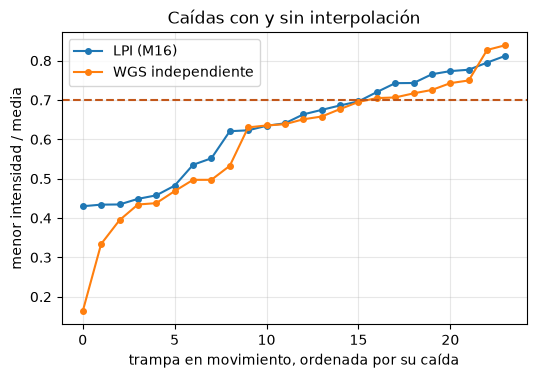

In [8]:
# la menor intensidad de cada trampa en movimiento en cada secuencia, ordenada
fig, ax = plt.subplots(figsize=(6.0, 3.8))
for name, r in ratios.items():
    ax.plot(np.sort(r), "o-", markersize=4, label=name)
ax.axhline(0.7, color="#c2571a", linestyle="--")
ax.set_xlabel("trampa en movimiento, ordenada por su caída")
ax.set_ylabel("menor intensidad / media")
ax.set_title("Caídas con y sin interpolación")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

Bajo el modelo de mezcla LPI tiene una peor trampa en movimiento en 0,430 de su media, una mediana de 0,652 y 33,3 por ciento de las trampas en movimiento en o sobre 0,7; los hologramas independientes tienen una peor trampa en 0,163, una mediana de 0,645 y la misma fracción de 33,3 por ciento. Las dos secuencias son iguales en el centro de la distribución y difieren en su cola: LPI mantiene su peor trampa 2,6 veces más alta que los hologramas independientes, que es lo que informa el artículo, el punto que casi desaparece. El modelo de mezcla es más estricto que la medida solo de cuadros de las celdas anteriores (una peor trampa de 0,690 para los mismos cuadros de LPI), porque cuenta los instantes entre cuadros, y es la lectura que el pipeline hace del artículo, marcada como no verificada en el método. La figura muestra una secuencia y una semilla, así que no dice cuán robusto es el factor de 2,6.

Un paso menor le da a LPI más cuadros sobre el mismo movimiento. La celda ejecuta M16 de nuevo con el exponente 1,5 y a lo más un bin por paso, en lugar de dos.

In [9]:
# LPI con un paso más fino: a lo más un bin por paso en lugar de dos, para alpha = 1.5
seq_fine = m16_rearrangement.run(setup, goal, budget=Budget(30), rng=Rng(1), atoms=atoms, alpha=1.5, max_step_bins=1.0)
ratio_fine = seq_fine.meta["min_ratio"][seq_fine.meta["moved"]]
print(f"{seq_fine.meta['n_steps']} pasos | menor intensidad de una trampa en movimiento, relativa a su media "
      f"{ratio_fine.min():.3f} | mediana {np.median(ratio_fine):.3f} | "
      f"fracción en o sobre 0.7 {np.mean(ratio_fine >= 0.7):.3f}")

18 pasos | menor intensidad de una trampa en movimiento, relativa a su media 0.701 | mediana 0.825 | fracción en o sobre 0.7 1.000


Con un paso de un bin la secuencia tiene 18 pasos, la menor intensidad de una trampa en movimiento sube de 0,690 a 0,701 y toda trampa en movimiento queda en o sobre 0,7, frente a 95,8 por ciento con el paso de dos bins; la mediana es 0,825 frente a 0,836. Un paso más fino compra la última trampa sobre la recta al precio de duplicar el número de hologramas, y no cambia el panorama de la secuencia. La medida es la de solo cuadros de M16, así que la ganancia no dice lo que mostrarían las mezclas entre cuadros.

## Resultados

**Respuesta:** La secuencia de hologramas que construye M16 mantiene las trampas en movimiento cerca de la recta del artículo y supera a los hologramas independientes en el peor caso. En el ordenamiento del caso C10, la secuencia del exponente 1,0 tiene 15 pasos y 16 trampas en movimiento cuya menor intensidad a lo largo de los cuadros es 0,710 de su media (mediana 0,857, todas sobre 0,7), y la del exponente 1,5 tiene 9 pasos y 24 trampas en movimiento con un mínimo de 0,690 (mediana 0,836, 95,8 por ciento sobre 0,7). Bajo el modelo de mezcla, más estricto, la peor trampa en movimiento de la secuencia de 1,5 está en 0,430 de su media con LPI y en 0,163 con un holograma independiente para cada paso, mientras las medianas son 0,652 y 0,645. Un paso más fino de a lo más un bin da 18 pasos, un mínimo de 0,701 y toda trampa sobre 0,7.

Lo que el notebook no muestra es una implementación independiente de LPI, que no existe entre las dependencias, ni la pérdida de un átomo que podrían causar las caídas.

## Resumen

- LPI construye los cuadros de un movimiento interpolando posición, amplitud y fase entre dos hologramas extremos, sin optimizar los cuadros.
- El número de pasos sigue el movimiento más largo de la asignación: 15 con el exponente 1,0 y 9 con 1,5.
- A lo largo de la secuencia las trampas en movimiento caen a entre 0,69 y 0,71 de su intensidad media, cerca del 0,7 del artículo.
- Los hologramas independientes para cada paso, la línea base del artículo, tienen una peor trampa en movimiento en 0,163 frente a 0,430 de LPI bajo el modelo de mezcla.
- No existe una implementación de referencia fijada de M16 entre las dependencias.

## Referencias

- Lee, Kim and Ahn (2017). Defect-free atomic array formation using the Hungarian matching algorithm. Physical Review A 95, 053424. https://doi.org/10.1103/PhysRevA.95.053424
- Parallel assembly of neutral atom arrays with an SLM using linear phase interpolation. https://arxiv.org/abs/2501.01391